In [35]:
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.model_selection import train_test_split

In [36]:
data = pd.read_csv("Divar_Assistant_5000.csv")
data

,product_type,brand,city,age_years,appearance,description,condition,price_toman
0,دوچرخه,دوچرخه پارس,تهران,14,درحدنو,این کالا را واگذار می‌کنم؛ دوچرخه؛ از نظر کارک...,سالم و قابل‌استفاده,7900000
1,دوچرخه,دوچرخه پارس,مشهد,11,متوسط,در صورت تمایل پیام بدهید؛ دوچرخه؛ به شکل فعلی ...,نیازمند تعمیر,5700000
2,لپ‌تاپ,لپ‌تاپ نوین,کرج,14,متوسط,قصد فروش دارم؛ لپ‌تاپ؛ برای مصرف معمولی آماده ...,سالم و قابل‌استفاده,20100000
3,مبل,مبل سپهر,اصفهان,13,خوب,این وسیله را می‌فروشم؛ مبل؛ فقط مصرف قطعات دار...,مناسب قطعات,3100000
4,دوچرخه,دوچرخه آریا,کرج,10,ضعیف,کالا موجود است؛ دوچرخه؛ بدون مشکل قابل استفاده...,سالم و قابل‌استفاده,7200000
...,...,...,...,...,...,...,...,...
4995,تلویزیون,تلویزیون نوین,تهران,8,خوب,برای فروش گذاشته‌ام؛ تلویزیون؛ برای استفاده عا...,مناسب قطعات,5200000
4996,لپ‌تاپ,لپ‌تاپ پارس,مشهد,2,ضعیف,برای فروش گذاشته‌ام؛ لپ‌تاپ؛ فقط برای استفاده ...,مناسب قطعات,8300000
4997,لپ‌تاپ,لپ‌تاپ نوین,مشهد,13,متوسط,آگهی فروش من است؛ لپ‌تاپ؛ قابل استفاده روزمره ...,مناسب قطعات,7100000
4998,مبل,مبل آریا,مشهد,14,خوب,دیگر به این وسیله نیاز ندارم؛ مبل؛ کارش را درس...,سالم و قابل‌استفاده,10200000


In [37]:
data_train,data_test = train_test_split(data,test_size=0.20)

data_train.to_csv("train.csv",index=False)
data_test.to_csv("test.csv",index=False)

In [38]:
data_train_text=data_train["description"]

y_train = data_train["condition"]

In [39]:
model=LinearSVC()

In [40]:
tfidf = TfidfVectorizer()

data_train_text_transformed = tfidf.fit_transform(data_train_text)

In [41]:
model.fit(data_train_text_transformed,y_train)

,"penalty penalty: {'l1', 'l2'}, default='l2'Specifies the norm used in the penalization. The 'l2'penalty is the standard used in SVC. The 'l1' leads to ``coef_``vectors that are sparse.",'l2'
,"loss loss: {'hinge', 'squared_hinge'}, default='squared_hinge'Specifies the loss function. 'hinge' is the standard SVM loss(used e.g. by the SVC class) while 'squared_hinge' is thesquare of the hinge loss. The combination of ``penalty='l1'``and ``loss='hinge'`` is not supported.",'squared_hinge'
,"dual dual: ""auto"" or bool, default=""auto""Select the algorithm to either solve the dual or primaloptimization problem. Prefer dual=False when n_samples > n_features.`dual=""auto""` will choose the value of the parameter automatically,based on the values of `n_samples`, `n_features`, `loss`, `multi_class`and `penalty`. If `n_samples` < `n_features` and optimizer supportschosen `loss`, `multi_class` and `penalty`, then dual will be set to True,otherwise it will be set to False... versionchanged:: 1.3 The `""auto""` option is added in version 1.3 and will be the default in version 1.5.",'auto'
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive.For an intuitive visualization of the effects of scalingthe regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"multi_class multi_class: {'ovr', 'crammer_singer'}, default='ovr'Determines the multi-class strategy if `y` contains more thantwo classes.``""ovr""`` trains n_classes one-vs-rest classifiers, while``""crammer_singer""`` optimizes a joint objective over all classes.While `crammer_singer` is interesting from a theoretical perspectiveas it is consistent, it is seldom used in practice as it rarely leadsto better accuracy and is more expensive to compute.If ``""crammer_singer""`` is chosen, the options loss, penalty and dualwill be ignored.",'ovr'
,"fit_intercept fit_intercept: bool, default=TrueWhether or not to fit an intercept. If set to True, the feature vectoris extended to include an intercept term: `[x_1, ..., x_n, 1]`, where1 corresponds to the intercept. If set to False, no intercept will beused in calculations (i.e. data is expected to be already centered).",True
,"intercept_scaling intercept_scaling: float, default=1.0When `fit_intercept` is True, the instance vector x becomes ``[x_1,..., x_n, intercept_scaling]``, i.e. a ""synthetic"" feature with aconstant value equal to `intercept_scaling` is appended to the instancevector. The intercept becomes intercept_scaling * synthetic featureweight. Note that liblinear internally penalizes the intercept,treating it like any other term in the feature vector. To reduce theimpact of the regularization on the intercept, the `intercept_scaling`parameter can be set to a value greater than 1; the higher the value of`intercept_scaling`, the lower the impact of regularization on it.Then, the weights become `[w_x_1, ..., w_x_n,w_intercept*intercept_scaling]`, where `w_x_1, ..., w_x_n` representthe feature weights and the intercept weight is scaled by`intercept_scaling`. This scaling allows the intercept term to have adifferent regularization behavior compared to the other features.",1
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to ``class_weight[i]*C`` forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: int, default=0Enable verbose output. Note that this setting takes advantage of aper-process runtime setting in liblinear that, if enabled, may not workproperly in a multithreaded context.",0
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo rand

In [42]:
data_test_text = data_test["description"]

In [43]:
data_test_text_transformed = tfidf.transform(data_test_text)

In [44]:
predictions = model.predict(data_test_text_transformed)
data_test["prediction_condition"]=predictions

In [45]:
condition_map = {"سالم و قابل‌استفاده":3,"نیازمند تعمیر":2,"مناسب قطعات":1}

data_test["condition"] = data_test["condition"].map(condition_map)
data_test["prediction_condition"] = data_test["prediction_condition"].map(condition_map)

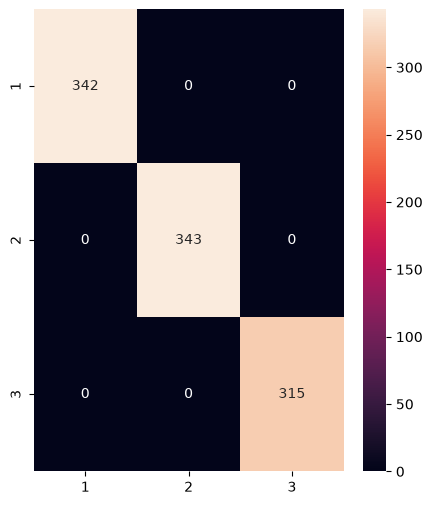

In [48]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import  matplotlib.pyplot  as plt 

predictions=data_test["prediction_condition"].values
truth=data_test["condition"].values

cm=confusion_matrix(truth,predictions,labels=[1,2,3])

plt.figure(figsize=(5,6))
sns.heatmap(cm,fmt="d",annot=True,xticklabels=[1,2,3],yticklabels=[1,2,3])

plt.show()

In [47]:
from sklearn.metrics import classification_report

print(classification_report(truth,predictions))

              precision    recall  f1-score   support

           1       1.00      1.00      1.00       342
           2       1.00      1.00      1.00       343
           3       1.00      1.00      1.00       315

    accuracy                           1.00      1000
   macro avg       1.00      1.00      1.00      1000
weighted avg       1.00      1.00      1.00      1000

